In [1]:
import sys
import torch
import yaml
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from ultralytics import YOLO

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA version:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

assert torch.cuda.is_available(), "CUDA is unavailable!"

print("GPU:", torch.cuda.get_device_name(0))

vram = torch.cuda.get_device_properties(0).total_memory
print("GPU VRAM:", round(vram / 1024**3, 2), "GB")

Python: C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\.venv\Scripts\python.exe
PyTorch: 2.5.1+cu124
CUDA version: 12.4
CUDA available: True
GPU: NVIDIA GeForce GTX 1650
GPU VRAM: 4.0 GB


In [2]:
DATASET_DIR = Path(
    r"C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\dataset"
).resolve()

In [3]:
import yaml

yaml_path = DATASET_DIR / "data.yaml"

with open(yaml_path, "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

names = config["names"]

if isinstance(names, dict):
    names = [
        names[k] for k in sorted(names, key=int)
    ]

print("Total classes:", len(names))

for i, name in enumerate(names):
    print(f"{i}: {name}")

assert len(names) == 17, "ERROR: Dataset is not 17 classes!"

if "nc" in config:
    assert int(config["nc"]) == 17

print("17-class dataset verified!")

Total classes: 17
0: broken-chipped-cut
1: dried-cherry-pod
2: floater
3: foreign-matter
4: full-black
5: full-sour
6: fungus-damage
7: good
8: husk
9: immature
10: parchment
11: partial-black
12: partial-sour
13: severe-insect-damage
14: shell
15: slight-insect-damage
16: withered
17-class dataset verified!


In [5]:
def resolve_split(split):
    value = config.get(split)

    if value is None:
        return None

    p = Path(value)

    if p.is_absolute():
        return p.resolve()

    candidates = [
        (DATASET_DIR / p).resolve(),
        (DATASET_DIR / p.name).resolve()
    ]

    for candidate in candidates:
        if candidate.exists():
            return candidate

    raise FileNotFoundError(
        f"Cannot locate {split}: {value}"
    )

train_path = resolve_split("train")
val_path = resolve_split("val")
test_path = resolve_split("test")

assert train_path is not None
assert val_path is not None

training_config = {
    "path": str(DATASET_DIR),
    "train": str(train_path),
    "val": str(val_path),
    "nc": 17,
    "names": names
}

if test_path is not None:
    training_config["test"] = str(test_path)

TRAIN_YAML = DATASET_DIR / "data.yaml"

with open(TRAIN_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(
        training_config,
        f,
        sort_keys=False
    )

print("Training YAML:", TRAIN_YAML)
print(yaml.safe_dump(training_config, sort_keys=False))

FileNotFoundError: Cannot locate train: ../train/images

In [6]:
from pathlib import Path

print("Current directory:", Path.cwd())
print("Dataset directory:", DATASET_DIR)
print("Dataset exists:", DATASET_DIR.exists())

print("\nDataset contents:")
for item in DATASET_DIR.iterdir():
    print(item.name, "[DIR]" if item.is_dir() else "[FILE]")

print("\nImage directories:")
for folder in DATASET_DIR.rglob("images"):
    if folder.is_dir():
        print(folder.resolve())

Current directory: C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C
Dataset directory: C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\dataset
Dataset exists: True

Dataset contents:
data.yaml [FILE]
README.dataset.txt [FILE]
README.roboflow.txt [FILE]
test [DIR]
train [DIR]
valid [DIR]

Image directories:
C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\dataset\test\images
C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\dataset\train\images
C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\dataset\valid\images


In [7]:
from pathlib import Path
import yaml

# Dataset location
DATASET_DIR = Path(
    r"C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\dataset"
)

# Actual image directories
train_path = DATASET_DIR / "train" / "images"
val_path = DATASET_DIR / "valid" / "images"
test_path = DATASET_DIR / "test" / "images"

# Verify directories
assert train_path.is_dir(), "Training images not found!"
assert val_path.is_dir(), "Validation images not found!"
assert test_path.is_dir(), "Test images not found!"

# Load original class definitions
with open(DATASET_DIR / "data.yaml", "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

names = config["names"]

if isinstance(names, dict):
    names = [names[k] for k in sorted(names, key=int)]

assert len(names) == 17, "Expected exactly 17 classes!"

# Create corrected YAML
training_config = {
    "path": str(DATASET_DIR),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 17,
    "names": names
}

TRAIN_YAML = DATASET_DIR / "cgi_17classes.yaml"

with open(TRAIN_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(
        training_config,
        f,
        sort_keys=False
    )

print("Training YAML created successfully!")
print("YAML path:", TRAIN_YAML)
print("Classes:", len(names))
print(yaml.safe_dump(training_config, sort_keys=False))

Training YAML created successfully!
YAML path: C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\dataset\cgi_17classes.yaml
Classes: 17
path: C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\dataset
train: train/images
val: valid/images
test: test/images
nc: 17
names:
- broken-chipped-cut
- dried-cherry-pod
- floater
- foreign-matter
- full-black
- full-sour
- fungus-damage
- good
- husk
- immature
- parchment
- partial-black
- partial-sour
- severe-insect-damage
- shell
- slight-insect-damage
- withered



In [8]:
from collections import Counter

class_counts = Counter()

for split_name, split_folder in [
    ("Train", DATASET_DIR / "train"),
    ("Validation", DATASET_DIR / "valid"),
    ("Test", DATASET_DIR / "test")
]:
    image_dir = split_folder / "images"
    label_dir = split_folder / "labels"

    assert label_dir.is_dir(), f"Missing labels: {label_dir}"

    images = [
        p for p in image_dir.rglob("*")
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    ]

    label_files = list(label_dir.rglob("*.txt"))

    print(f"\n{split_name}:")
    print("Images:", len(images))
    print("Label files:", len(label_files))

    for label_file in label_files:
        for line in label_file.read_text().splitlines():
            if not line.strip():
                continue

            parts = line.split()

            assert len(parts) == 5, (
                f"Invalid detection label: {label_file}"
            )

            class_id = int(parts[0])
            coordinates = [float(x) for x in parts[1:]]

            assert 0 <= class_id < 17
            assert all(0 <= x <= 1 for x in coordinates)

            class_counts[class_id] += 1

print("\nAnnotations per class:")

for i, name in enumerate(names):
    print(f"{i}: {name} — {class_counts[i]}")


Train:
Images: 6081
Label files: 6081

Validation:
Images: 563
Label files: 563

Test:
Images: 306
Label files: 306

Annotations per class:
0: broken-chipped-cut — 1611
1: dried-cherry-pod — 179
2: floater — 221
3: foreign-matter — 161
4: full-black — 2371
5: full-sour — 279
6: fungus-damage — 1528
7: good — 1624
8: husk — 1793
9: immature — 1084
10: parchment — 384
11: partial-black — 433
12: partial-sour — 1556
13: severe-insect-damage — 663
14: shell — 792
15: slight-insect-damage — 1024
16: withered — 32


In [9]:
import torch
from ultralytics import YOLO

assert torch.cuda.is_available(), "CUDA is not available!"

model = YOLO("yolov8n.pt")

results = model.train(
    data=str(TRAIN_YAML),
    epochs=100,
    imgsz=640,
    batch=4,
    device=0,
    workers=0,
    patience=100,
    optimizer="auto",
    amp=True,
    seed=42,
    plots=True,
    save=True,
    project=str(DATASET_DIR.parent / "CGI_Training_Results"),
    name="YOLOv8n_17Classes_100Epochs",
    exist_ok=False
)

Ultralytics 8.4.190  Python-3.11.9 torch-2.5.1+cu124 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\dataset\cgi_17classes.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLOv8n_17C

In [1]:
from pathlib import Path
from ultralytics import YOLO

import torch
import yaml
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from IPython.display import display, Image

BASE_DIR = Path(
    r"C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C"
)

DATASET_DIR = BASE_DIR / "dataset"
TRAIN_YAML = DATASET_DIR / "cgi_17classes.yaml"

RESULTS_DIR = BASE_DIR / "CGI_Training_Results"

# Find completed training runs
runs = sorted(
    RESULTS_DIR.glob("YOLOv8n_17Classes_100Epochs*"),
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

for run in runs:
    print(run)

assert runs, "No training run found!"

# Uses the most recently modified matching run
RUN_DIR = runs[0]

BEST_MODEL = RUN_DIR / "weights" / "best.pt"
LAST_MODEL = RUN_DIR / "weights" / "last.pt"

assert BEST_MODEL.exists(), "best.pt not found!"
assert TRAIN_YAML.exists(), "Training YAML not found!"

print("\nSelected run:", RUN_DIR)
print("Best model:", BEST_MODEL)
print("Last model:", LAST_MODEL)

print("\nCUDA available:", torch.cuda.is_available())

device = 0 if torch.cuda.is_available() else "cpu"

model = YOLO(str(BEST_MODEL))

print("Model loaded successfully!")
print("Classes:", len(model.names))

C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\CGI_Training_Results\YOLOv8n_17Classes_100Epochs

Selected run: C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\CGI_Training_Results\YOLOv8n_17Classes_100Epochs
Best model: C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\CGI_Training_Results\YOLOv8n_17Classes_100Epochs\weights\best.pt
Last model: C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\CGI_Training_Results\YOLOv8n_17Classes_100Epochs\weights\last.pt

CUDA available: True
Model loaded successfully!
Classes: 17


In [2]:
print("MODEL INFORMATION")
print("-" * 45)

for class_id, class_name in model.names.items():
    print(f"{class_id}: {class_name}")

assert len(model.names) == 17, (
    "Model does not contain 17 classes!"
)

print("\n17-class model verified.")

MODEL INFORMATION
---------------------------------------------
0: broken-chipped-cut
1: dried-cherry-pod
2: floater
3: foreign-matter
4: full-black
5: full-sour
6: fungus-damage
7: good
8: husk
9: immature
10: parchment
11: partial-black
12: partial-sour
13: severe-insect-damage
14: shell
15: slight-insect-damage
16: withered

17-class model verified.


In [3]:
with open(TRAIN_YAML, "r", encoding="utf-8") as f:
    data_config = yaml.safe_load(f)

evaluation_split = (
    "test" if data_config.get("test") else "val"
)

metrics = model.val(
    data=str(TRAIN_YAML),
    split=evaluation_split,
    imgsz=640,
    batch=2,
    device=device,
    workers=0,
    plots=True,
    project=str(BASE_DIR / "CGI_Evaluation"),
    name="YOLOv8n_100Epochs_Test",
    exist_ok=False
)

print("\nEVALUATION COMPLETE")
print("Split:", evaluation_split)
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.190  Python-3.11.9 torch-2.5.1+cu124 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
Model summary (fused): 73 layers, 3,136,595 parameters, 0 gradients, 8.7 GFLOPs
WARNING val: Slow image access detected (ping: 0.1±0.0 ms, read: 23.6±3.2 MB/s, size: 148.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\dataset\test\labels... 306 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 306/306 339.7it/s 0.9s0.1s
val: New cache created: C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\dataset\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 153/153 16.7it/s 9.2s0.1s
                   all        306        612      0.715      0.624      0.683      0.587
    broken-chipped-cut         32         66      0.665      0.439      0.621       0.52
      dried-cherry-pod        

In [4]:
overall_metrics = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "mAP@50",
        "mAP@50-95"
    ],
    "Score": [
        metrics.box.mp,
        metrics.box.mr,
        metrics.box.map50,
        metrics.box.map
    ]
})

overall_metrics["Percentage (%)"] = (
    overall_metrics["Score"] * 100
).round(2)

display(overall_metrics)

,Metric,Score,Percentage (%)
0,Precision,0.715330,71.53
1,Recall,0.623880,62.39
2,mAP@50,0.683070,68.31
3,mAP@50-95,0.586752,58.68


In [5]:
box = metrics.box

class_ids = box.ap_class_index.astype(int)

per_class_results = pd.DataFrame({
    "Class ID": class_ids,
    "Class Name": [
        model.names[int(i)] for i in class_ids
    ],
    "Precision": box.p,
    "Recall": box.r,
    "mAP50": box.ap50,
    "mAP50-95": box.ap
})

metric_columns = [
    "Precision",
    "Recall",
    "mAP50",
    "mAP50-95"
]

per_class_results[metric_columns] = (
    per_class_results[metric_columns] * 100
).round(2)

display(
    per_class_results.sort_values(
        "mAP50",
        ascending=False
    )
)

,Class ID,Class Name,Precision,Recall,mAP50,mAP50-95
3,3,foreign-matter,100.00,94.82,99.50,83.00
4,4,full-black,92.20,92.31,97.30,83.65
8,8,husk,87.78,91.18,95.99,79.63
7,7,good,89.63,85.00,89.05,78.27
14,14,shell,75.43,70.19,83.18,71.04
6,6,fungus-damage,65.32,78.46,80.25,67.94
15,15,slight-insect-damage,78.85,69.39,78.10,63.36
12,12,partial-sour,58.46,82.51,72.05,67.62
9,9,immature,68.66,68.00,70.44,63.98
5,5,full-sour,69.37,53.33,65.90,63.38


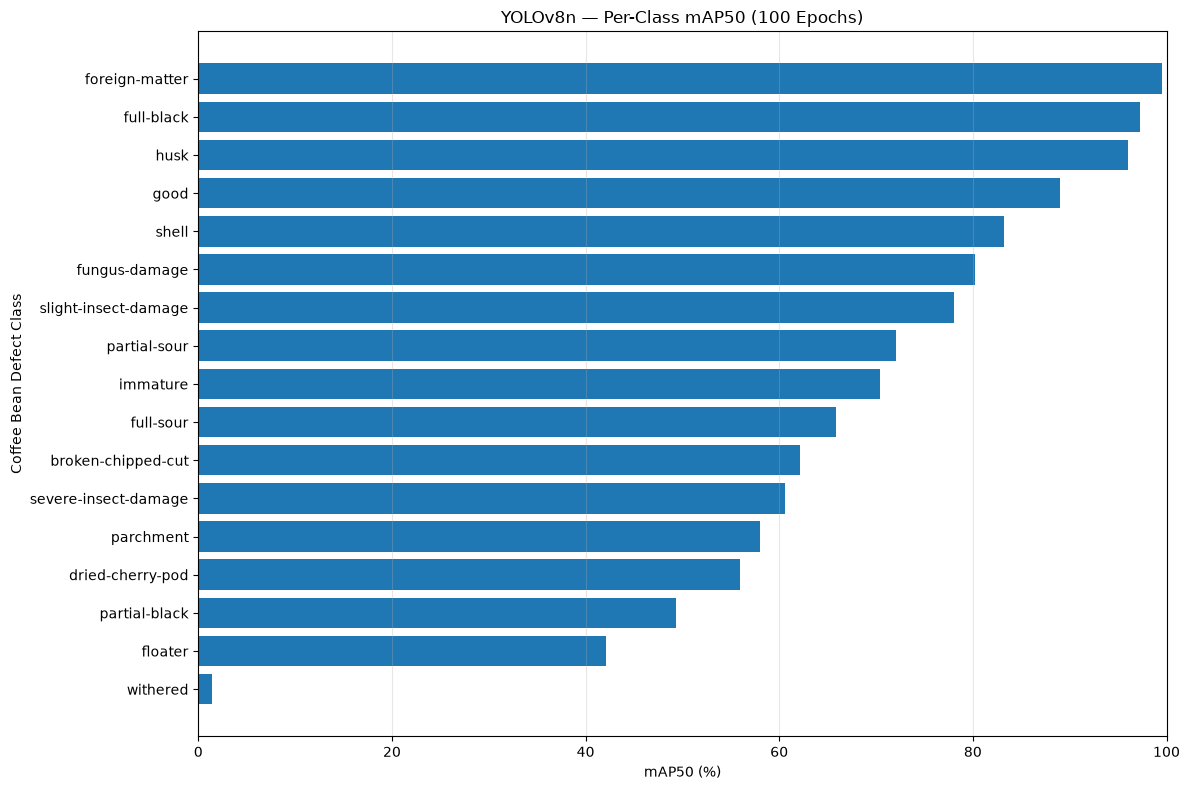

In [6]:
plot_data = per_class_results.sort_values("mAP50")

plt.figure(figsize=(12, 8))

plt.barh(
    plot_data["Class Name"],
    plot_data["mAP50"]
)

plt.xlabel("mAP50 (%)")
plt.ylabel("Coffee Bean Defect Class")
plt.title("YOLOv8n — Per-Class mAP50 (100 Epochs)")
plt.xlim(0, 100)
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

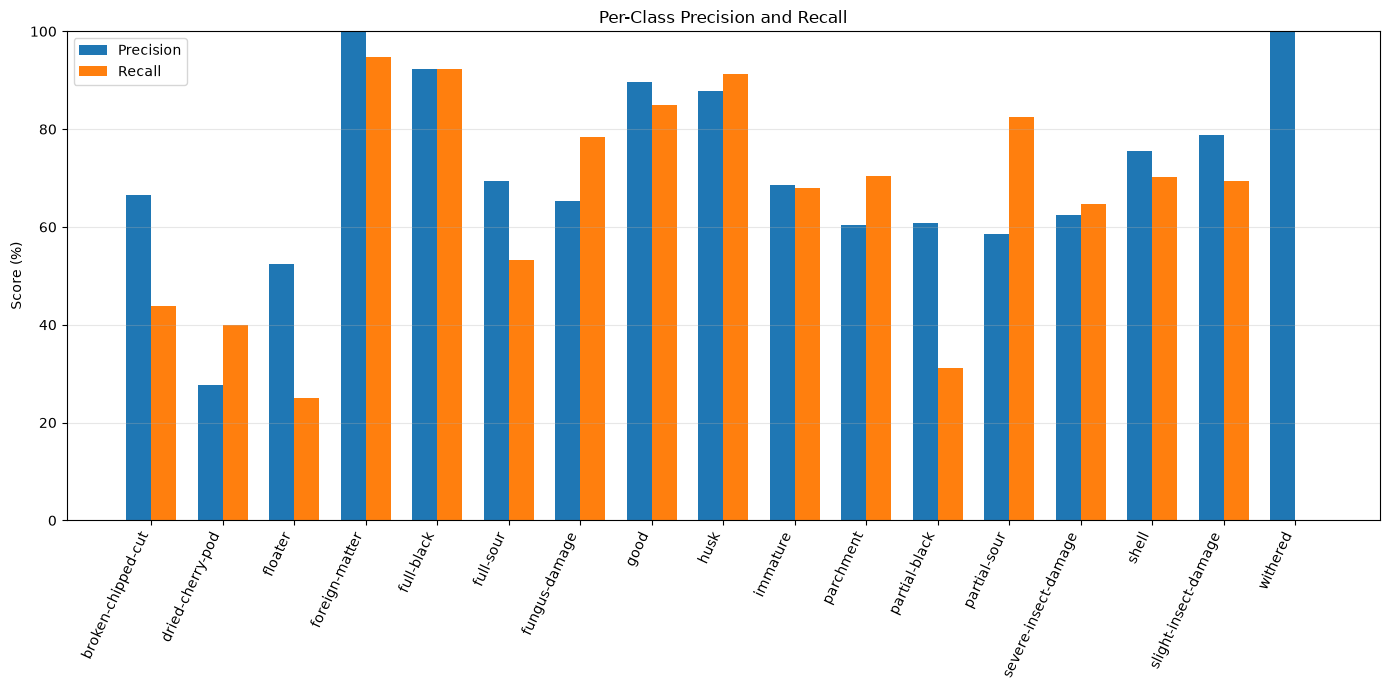

In [7]:
plot_data = per_class_results.sort_values(
    "Class ID"
)

x = np.arange(len(plot_data))
width = 0.35

plt.figure(figsize=(14, 7))

plt.bar(
    x - width / 2,
    plot_data["Precision"],
    width,
    label="Precision"
)

plt.bar(
    x + width / 2,
    plot_data["Recall"],
    width,
    label="Recall"
)

plt.xticks(
    x,
    plot_data["Class Name"],
    rotation=65,
    ha="right"
)

plt.ylabel("Score (%)")
plt.title("Per-Class Precision and Recall")
plt.ylim(0, 100)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

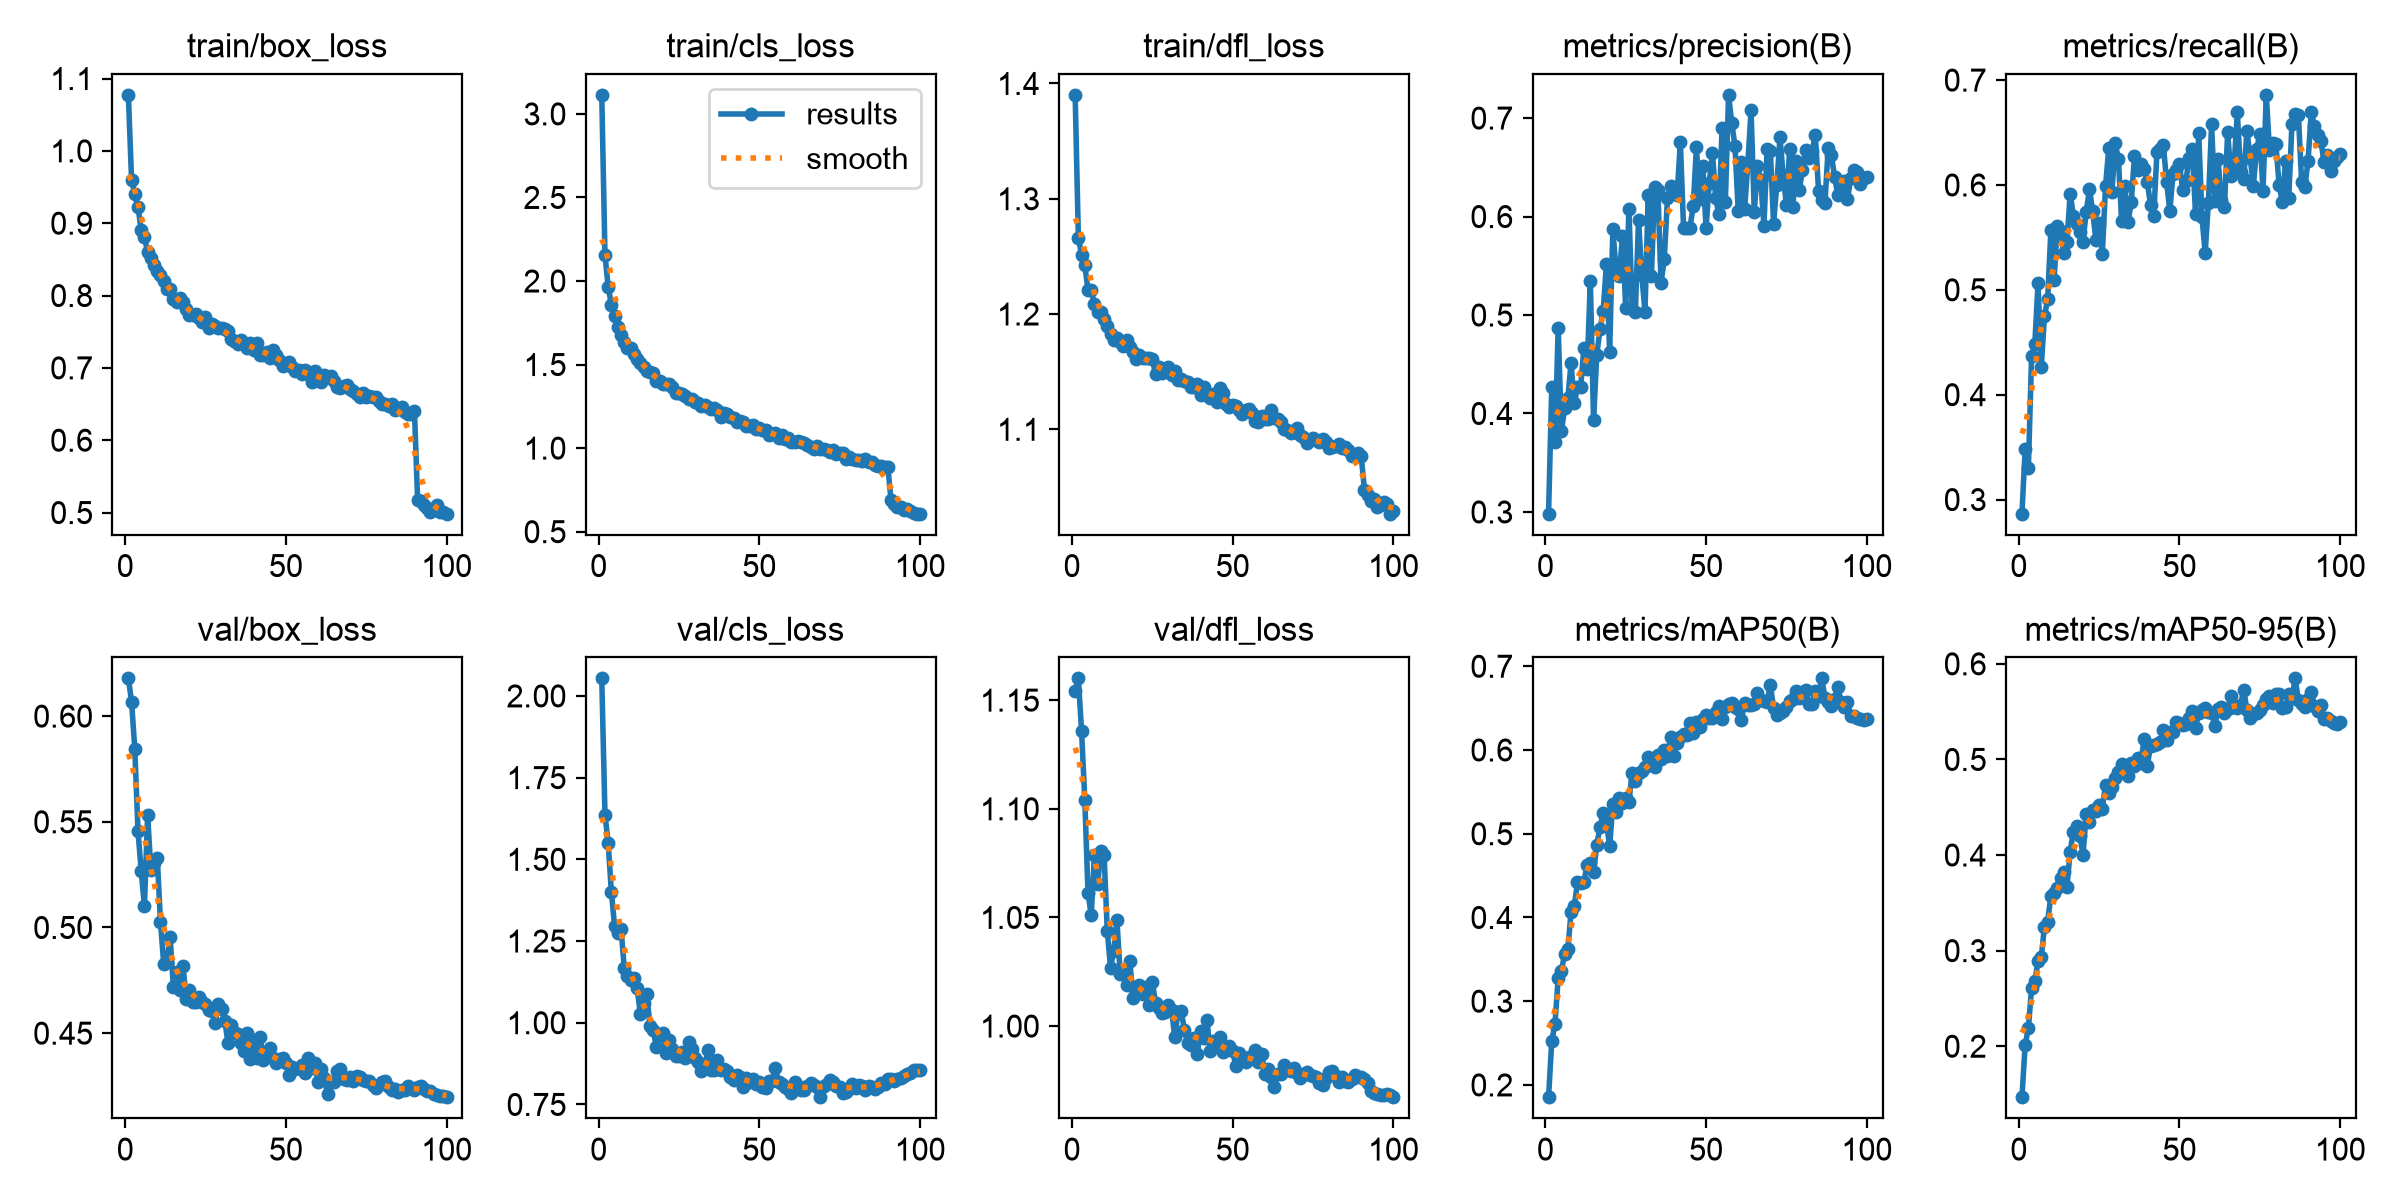

In [8]:
results_image = RUN_DIR / "results.png"

if results_image.exists():
    display(
        Image(filename=str(results_image))
    )
else:
    print("results.png not found.")

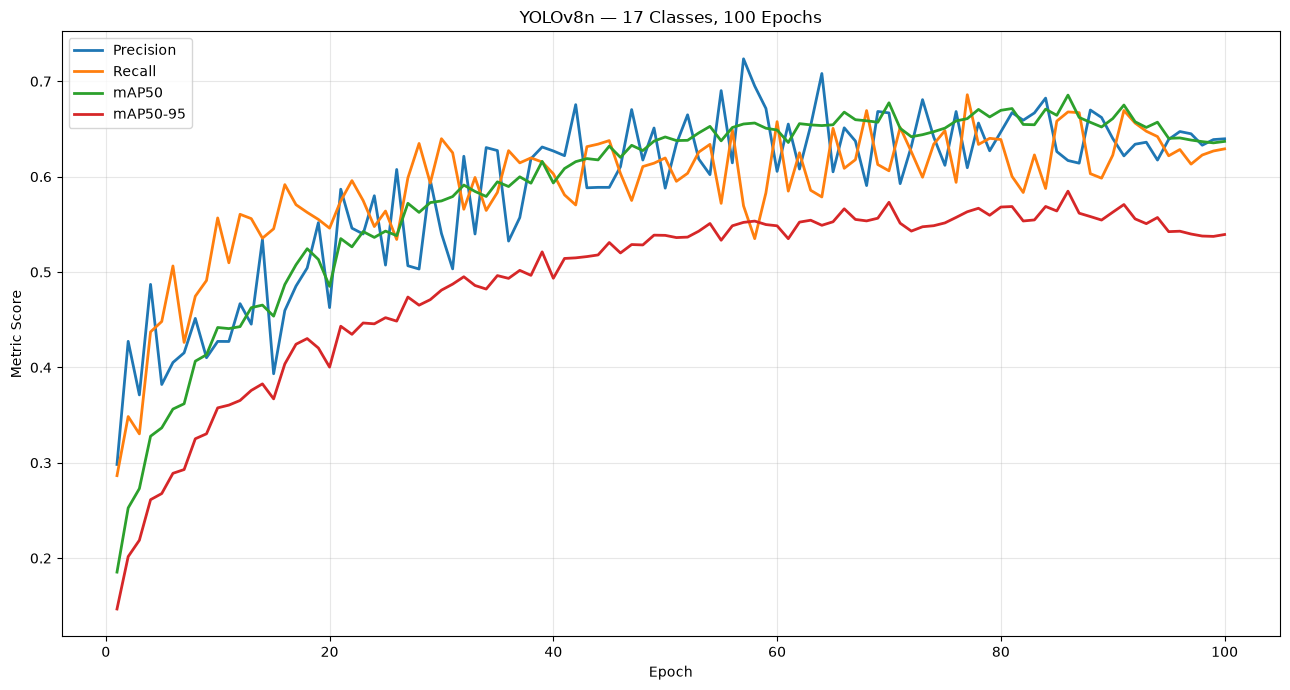

In [9]:
history = pd.read_csv(
    RUN_DIR / "results.csv"
)

history.columns = history.columns.str.strip()

metric_columns = {
    "metrics/precision(B)": "Precision",
    "metrics/recall(B)": "Recall",
    "metrics/mAP50(B)": "mAP50",
    "metrics/mAP50-95(B)": "mAP50-95"
}

plt.figure(figsize=(13, 7))

for column, label in metric_columns.items():
    if column in history.columns:
        plt.plot(
            history["epoch"],
            history[column],
            label=label,
            linewidth=2
        )

plt.xlabel("Epoch")
plt.ylabel("Metric Score")
plt.title("YOLOv8n — 17 Classes, 100 Epochs")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

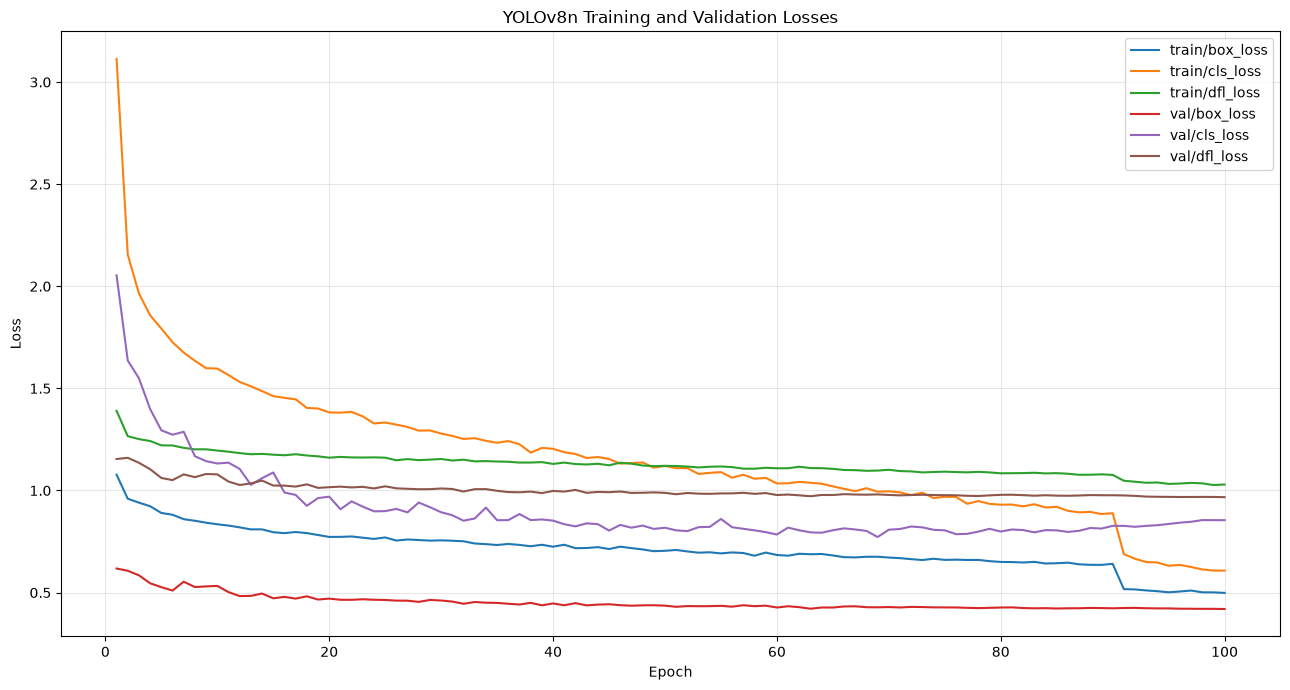

In [10]:
loss_columns = [
    "train/box_loss",
    "train/cls_loss",
    "train/dfl_loss",
    "val/box_loss",
    "val/cls_loss",
    "val/dfl_loss"
]

plt.figure(figsize=(13, 7))

for column in loss_columns:
    if column in history.columns:
        plt.plot(
            history["epoch"],
            history[column],
            label=column
        )

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("YOLOv8n Training and Validation Losses")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

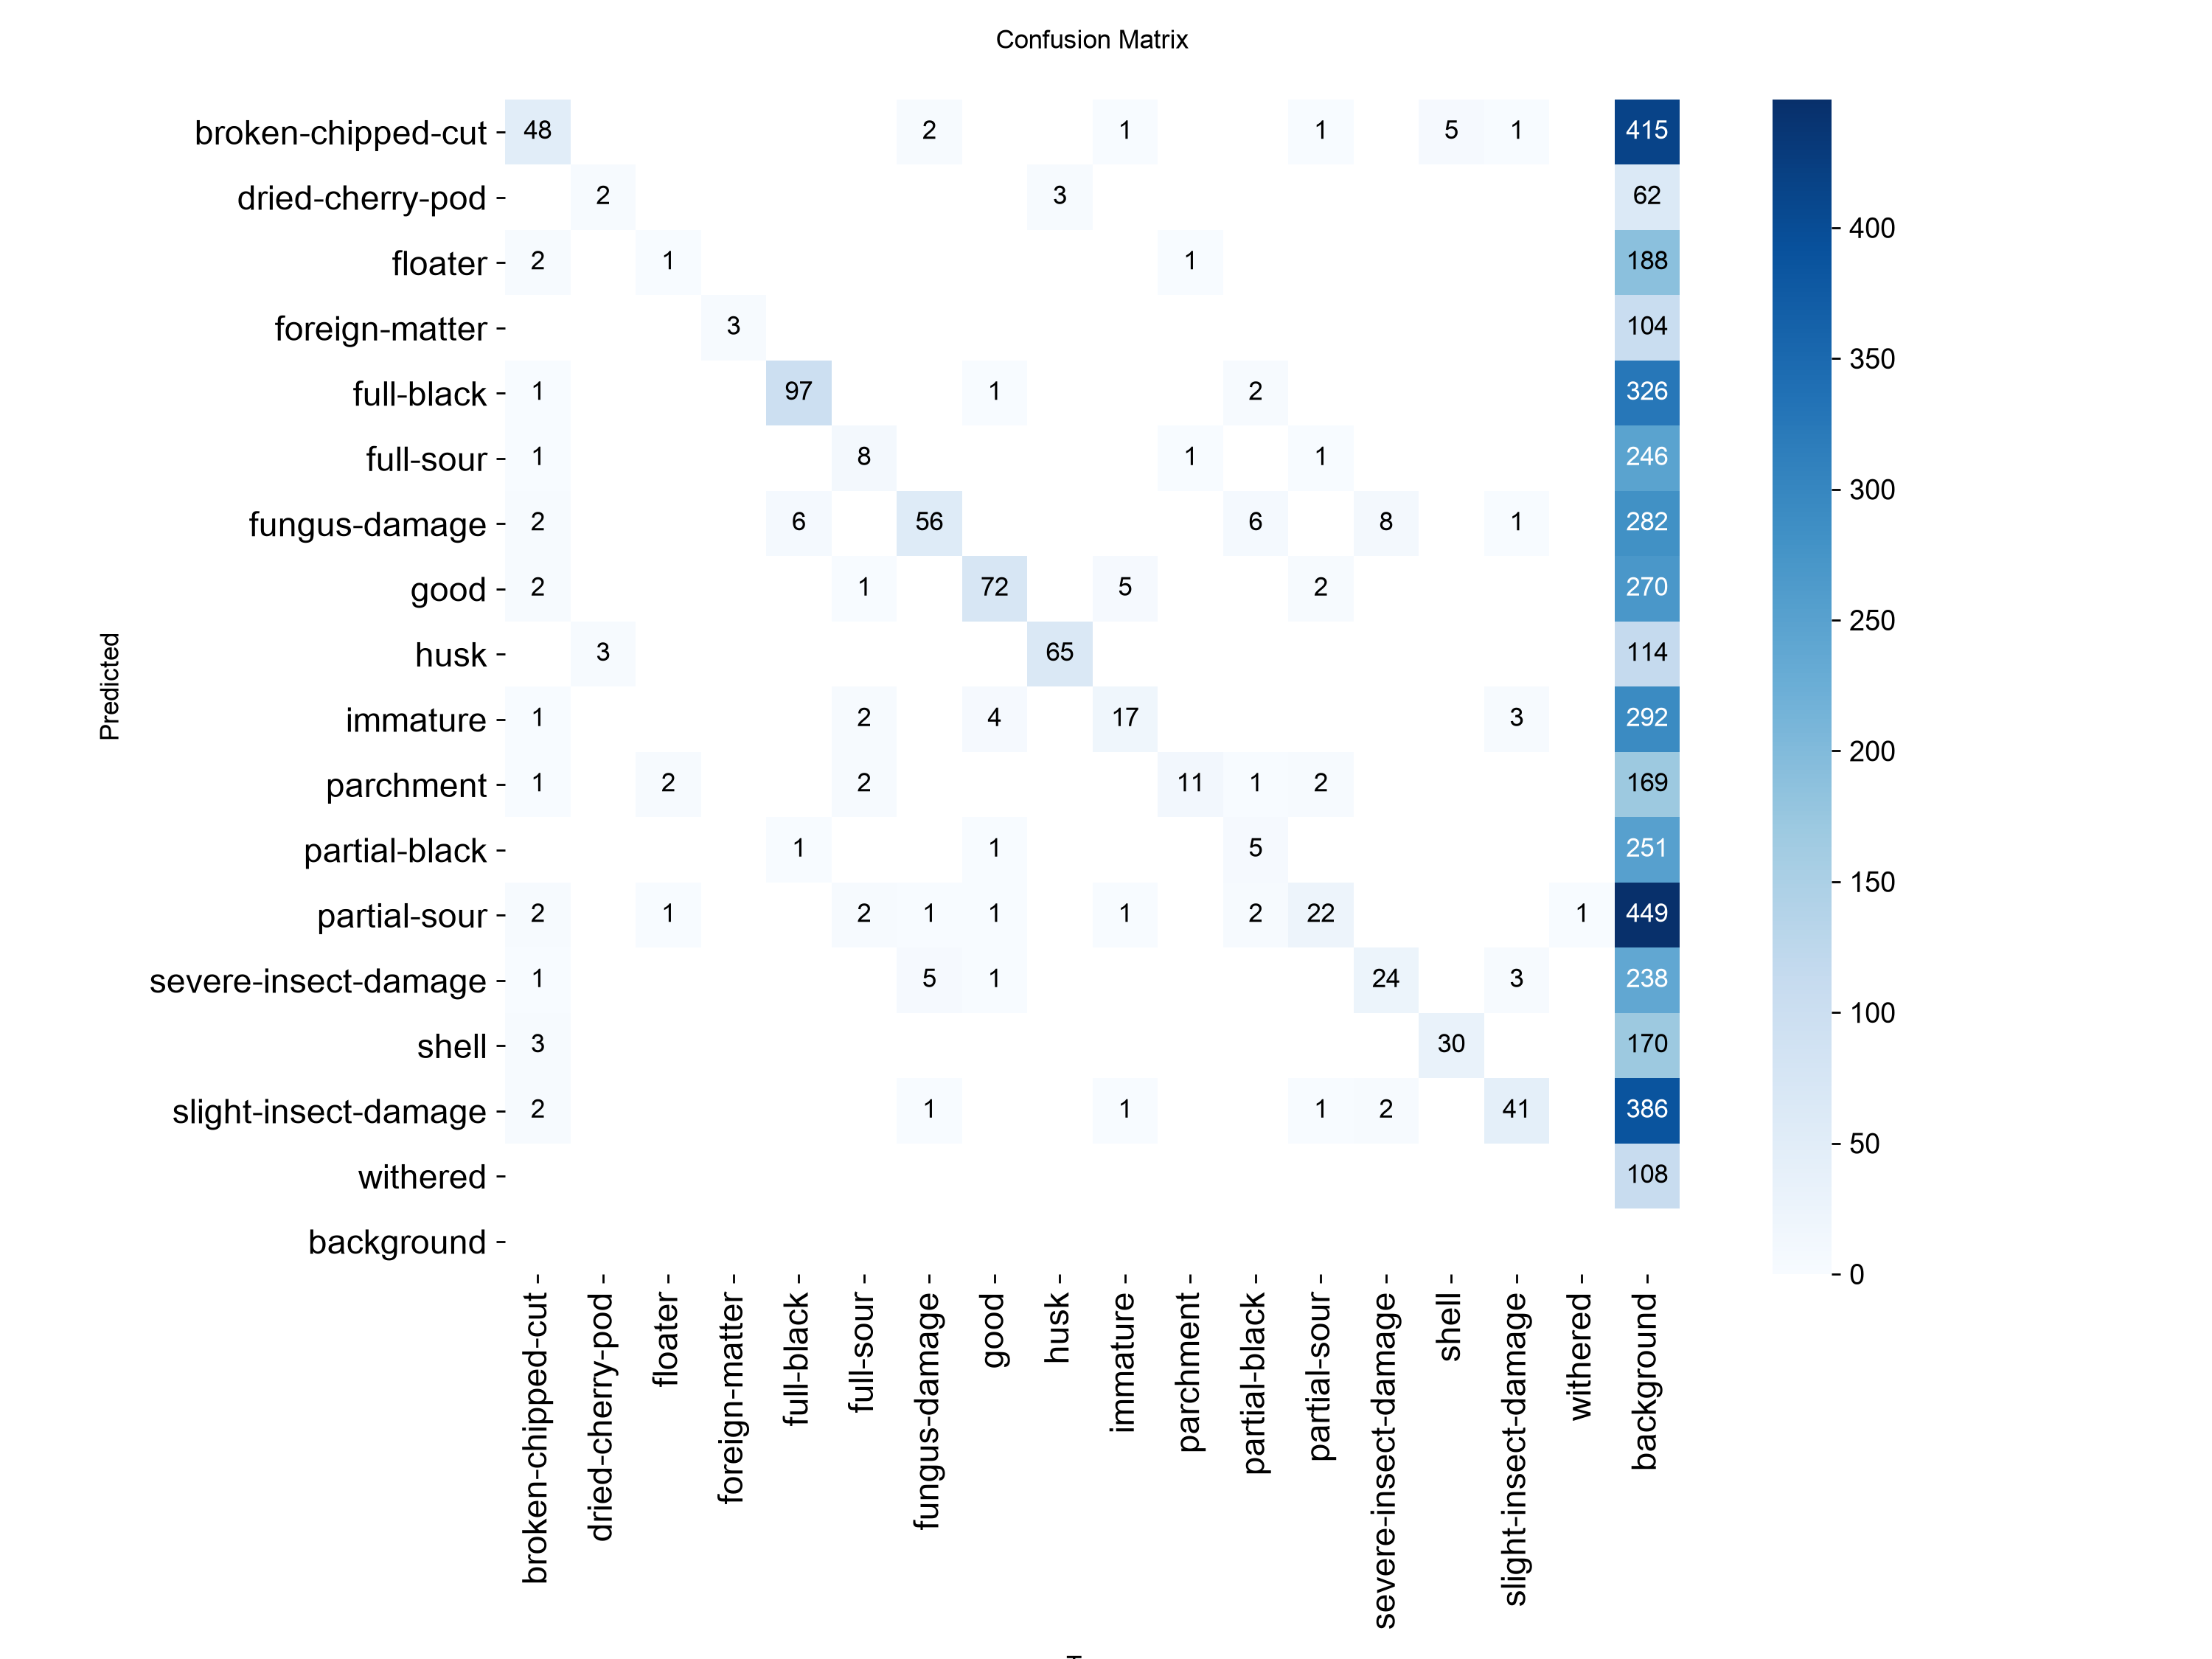

In [11]:
EVAL_DIR = Path(metrics.save_dir)

confusion_matrix = (
    EVAL_DIR / "confusion_matrix.png"
)

if confusion_matrix.exists():
    display(
        Image(filename=str(confusion_matrix))
    )
else:
    print("Confusion matrix not found.")

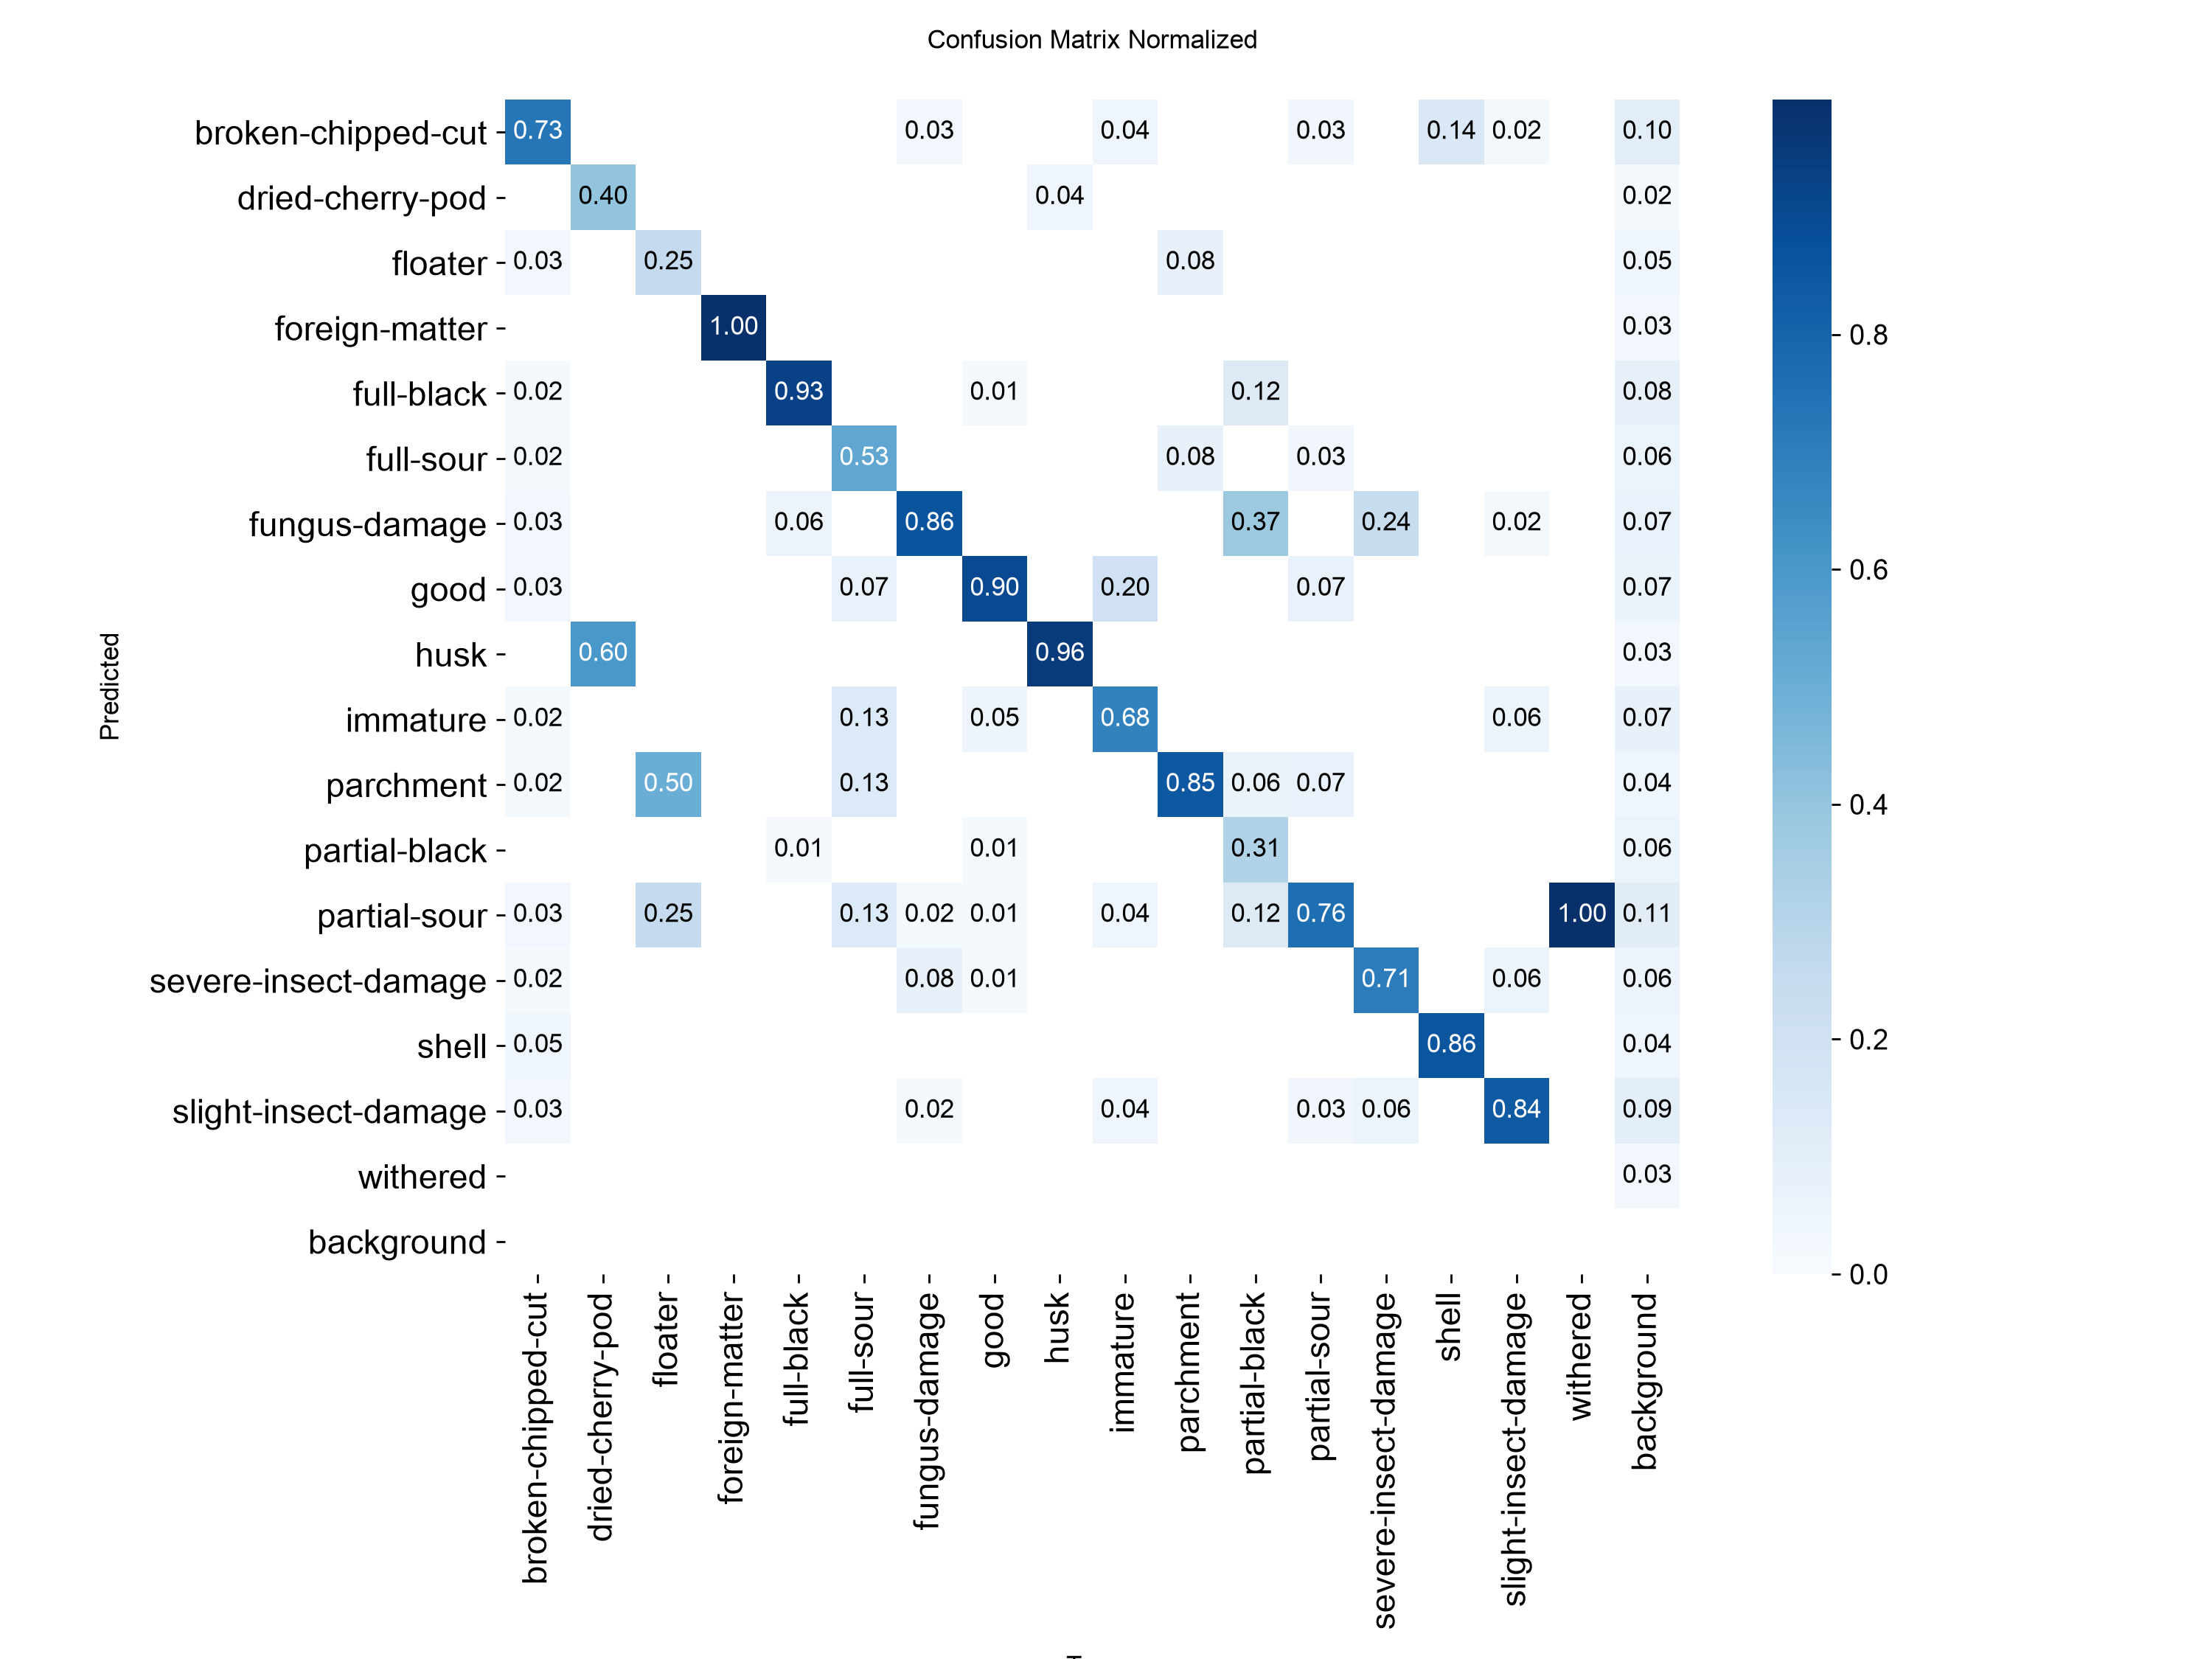

In [12]:
normalized_matrix = (
    EVAL_DIR / "confusion_matrix_normalized.png"
)

if normalized_matrix.exists():
    display(
        Image(filename=str(normalized_matrix))
    )
else:
    print("Normalized confusion matrix not found.")

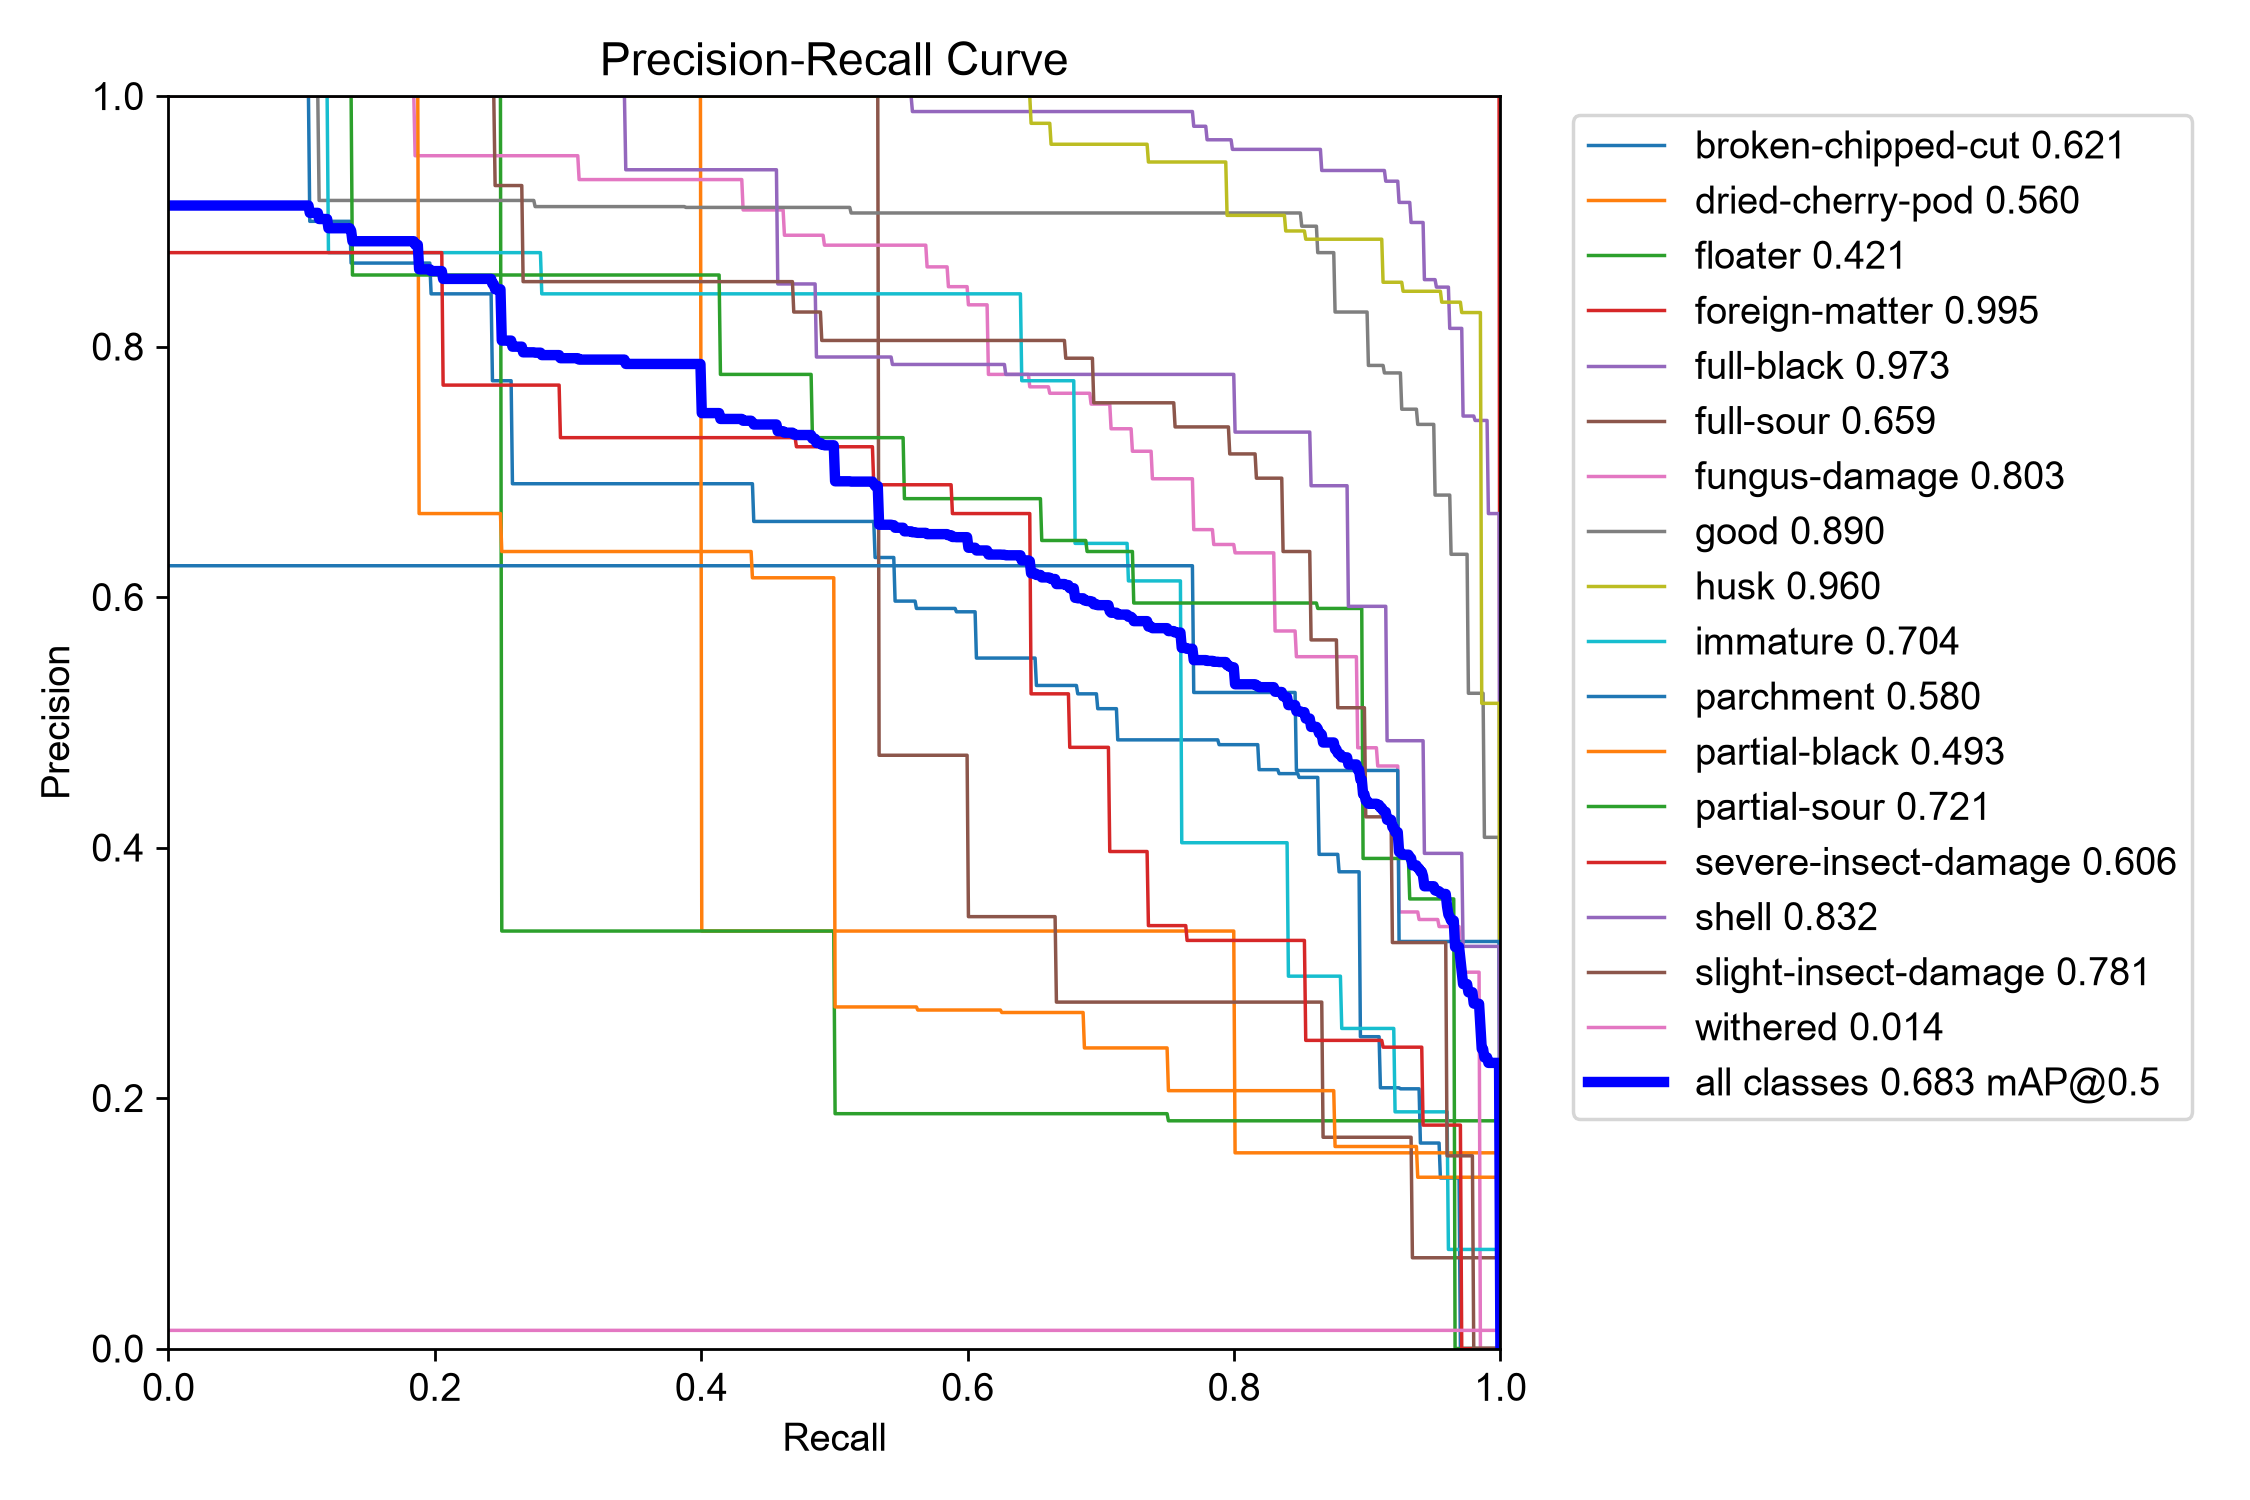

In [13]:
pr_curve = EVAL_DIR / "BoxPR_curve.png"

if pr_curve.exists():
    display(Image(filename=str(pr_curve)))
else:
    print("Precision–Recall curve not found.")


image 1/1 C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\B001-BL-B1.jpg: 640x480 (no detections), 57.0ms
Speed: 6.2ms preprocess, 57.0ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 480)
Results saved to C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\runs\detect\predict


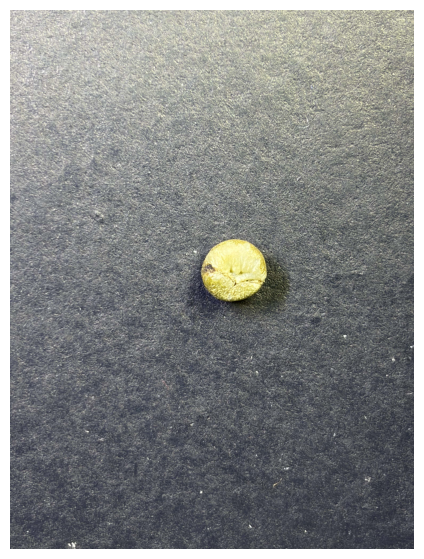

In [15]:
new_image = r"C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\B001-BL-B1.jpg"

results_new = model.predict(
    source=new_image,
    conf=0.25,
    imgsz=640,
    device=device,
    save=True
)

for result in results_new:
    plt.figure(figsize=(10, 7))
    plt.imshow(result.plot()[:, :, ::-1])
    plt.axis("off")
    plt.show()


image 1/1 C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\B001-SB-B1.jpg: 640x480 1 fungus-damage, 51.4ms
Speed: 4.8ms preprocess, 51.4ms inference, 3.2ms postprocess per image at shape (1, 3, 640, 480)
Results saved to C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\runs\detect\predict


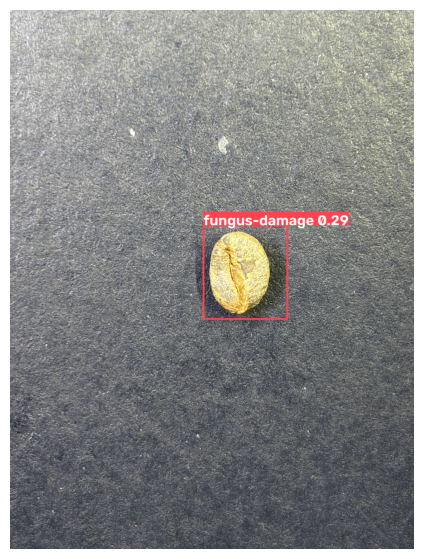

In [16]:
new_image = r"C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\B001-SB-B1.jpg"

results_new = model.predict(
    source=new_image,
    conf=0.25,
    imgsz=640,
    device=device,
    save=True
)

for result in results_new:
    plt.figure(figsize=(10, 7))
    plt.imshow(result.plot()[:, :, ::-1])
    plt.axis("off")
    plt.show()


image 1/1 C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\log.jpg: 640x640 1 husk, 90.7ms
Speed: 6.8ms preprocess, 90.7ms inference, 3.0ms postprocess per image at shape (1, 3, 640, 640)
Results saved to C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\runs\detect\predict


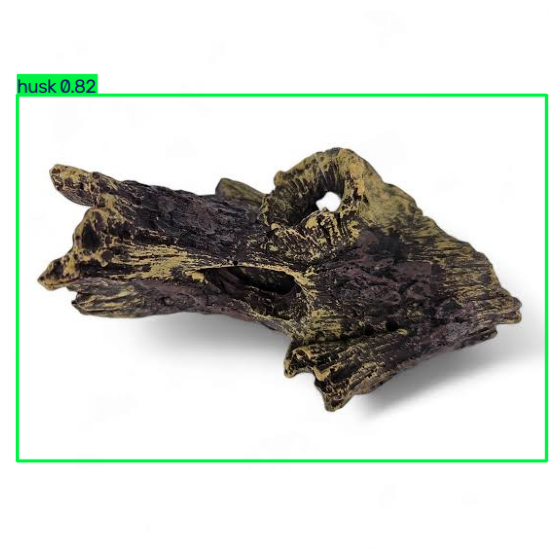

In [17]:
new_image = r"C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\log.jpg"

results_new = model.predict(
    source=new_image,
    conf=0.25,
    imgsz=640,
    device=device,
    save=True
)

for result in results_new:
    plt.figure(figsize=(10, 7))
    plt.imshow(result.plot()[:, :, ::-1])
    plt.axis("off")
    plt.show()


image 1/1 C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\B007-BL-F1.jpg: 640x480 (no detections), 10.4ms
Speed: 2.0ms preprocess, 10.4ms inference, 0.5ms postprocess per image at shape (1, 3, 640, 480)
Results saved to C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\runs\detect\predict


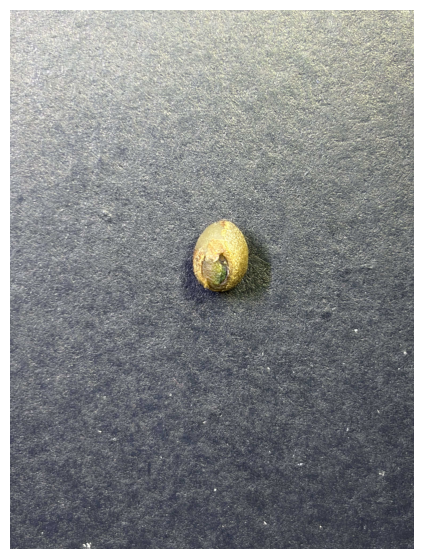

In [18]:
new_image = r"C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\B007-BL-F1.jpg"

results_new = model.predict(
    source=new_image,
    conf=0.25,
    imgsz=640,
    device=device,
    save=True
)

for result in results_new:
    plt.figure(figsize=(10, 7))
    plt.imshow(result.plot()[:, :, ::-1])
    plt.axis("off")
    plt.show()


image 1/1 C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\B007-BL-F1.jpg: 640x480 (no detections), 69.0ms
Speed: 5.0ms preprocess, 69.0ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 480)
Results saved to C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\runs\detect\predict


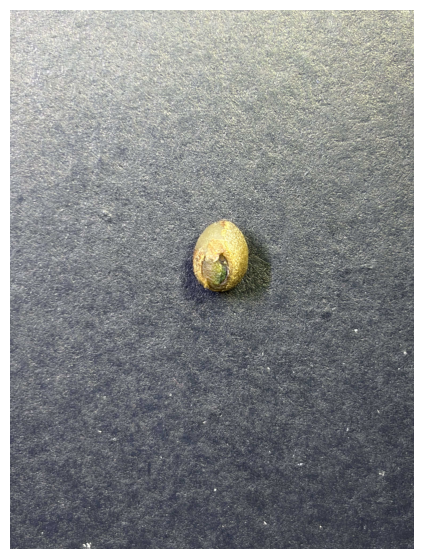

In [19]:
new_image = r"C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\B007-BL-F1.jpg"

results_new = model.predict(
    source=new_image,
    conf=0.25,
    imgsz=640,
    device=device,
    save=True
)

for result in results_new:
    plt.figure(figsize=(10, 7))
    plt.imshow(result.plot()[:, :, ::-1])
    plt.axis("off")
    plt.show()


image 1/1 C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\B007-BL-F3.jpg: 640x480 (no detections), 54.2ms
Speed: 4.6ms preprocess, 54.2ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 480)
Results saved to C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\runs\detect\predict


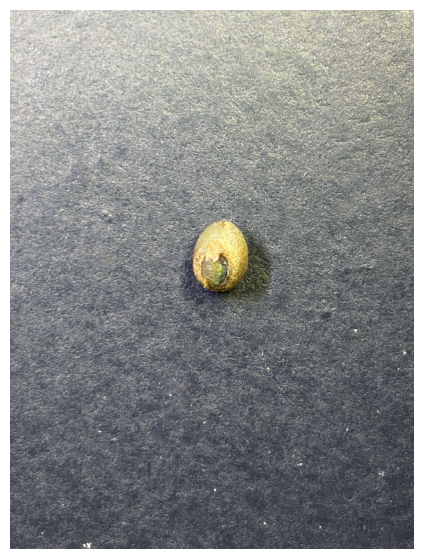

In [20]:
new_image = r"C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\B007-BL-F3.jpg"

results_new = model.predict(
    source=new_image,
    conf=0.25,
    imgsz=640,
    device=device,
    save=True
)

for result in results_new:
    plt.figure(figsize=(10, 7))
    plt.imshow(result.plot()[:, :, ::-1])
    plt.axis("off")
    plt.show()


image 1/1 C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\B008-BL-B2.jpg: 640x480 (no detections), 52.6ms
Speed: 4.5ms preprocess, 52.6ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 480)
Results saved to C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\runs\detect\predict


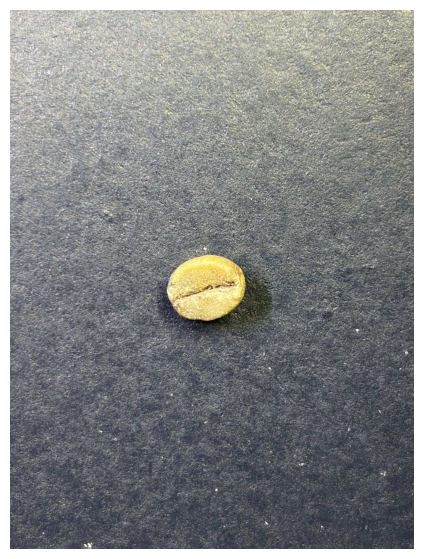

In [21]:
new_image = r"C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\B008-BL-B2.jpg"

results_new = model.predict(
    source=new_image,
    conf=0.25,
    imgsz=640,
    device=device,
    save=True
)

for result in results_new:
    plt.figure(figsize=(10, 7))
    plt.imshow(result.plot()[:, :, ::-1])
    plt.axis("off")
    plt.show()


image 1/1 C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\B001-BB-B1.jpg: 640x480 1 fungus-damage, 70.2ms
Speed: 5.2ms preprocess, 70.2ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 480)
Results saved to C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\runs\detect\predict


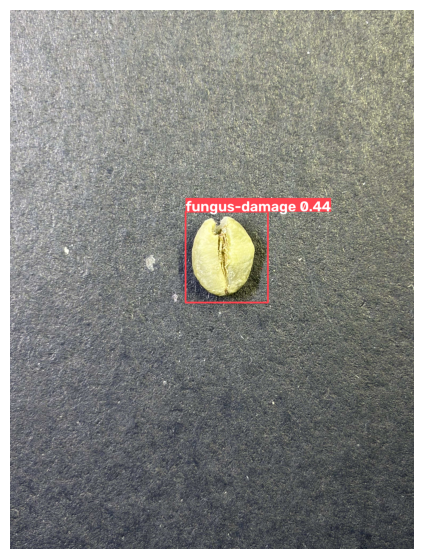

In [22]:
new_image = r"C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\B001-BB-B1.jpg"

results_new = model.predict(
    source=new_image,
    conf=0.25,
    imgsz=640,
    device=device,
    save=True
)

for result in results_new:
    plt.figure(figsize=(10, 7))
    plt.imshow(result.plot()[:, :, ::-1])
    plt.axis("off")
    plt.show()


image 1/1 C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\202309260254-LCPXL4.jpg: 416x640 1 broken-chipped-cut, 8 fungus-damages, 72.3ms
Speed: 4.6ms preprocess, 72.3ms inference, 2.2ms postprocess per image at shape (1, 3, 416, 640)
Results saved to C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\runs\detect\predict


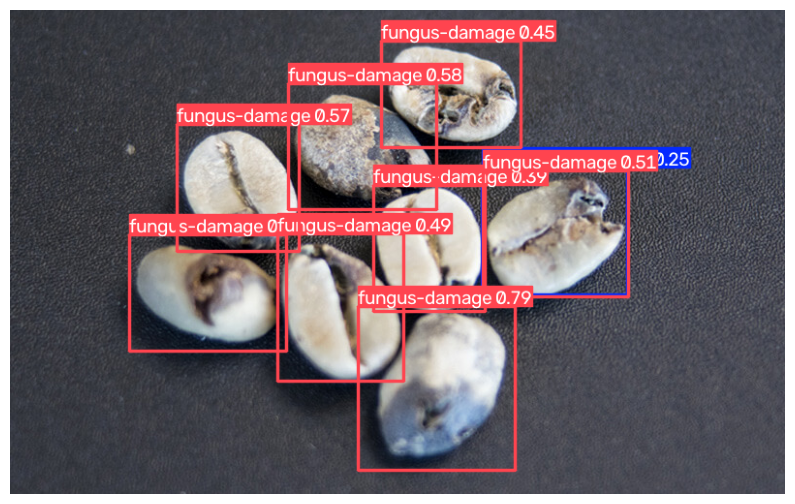

In [23]:
new_image = r"C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\202309260254-LCPXL4.jpg"

results_new = model.predict(
    source=new_image,
    conf=0.25,
    imgsz=640,
    device=device,
    save=True
)

for result in results_new:
    plt.figure(figsize=(10, 7))
    plt.imshow(result.plot()[:, :, ::-1])
    plt.axis("off")
    plt.show()


image 1/1 C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\B014-BB-B2.jpg: 640x480 (no detections), 71.6ms
Speed: 5.1ms preprocess, 71.6ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 480)
Results saved to C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\runs\detect\predict


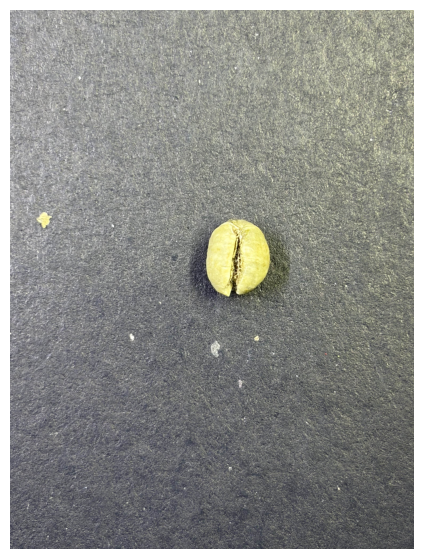

In [24]:
new_image = r"C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\B014-BB-B2.jpg"

results_new = model.predict(
    source=new_image,
    conf=0.25,
    imgsz=640,
    device=device,
    save=True
)

for result in results_new:
    plt.figure(figsize=(10, 7))
    plt.imshow(result.plot()[:, :, ::-1])
    plt.axis("off")
    plt.show()


image 1/1 C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\B015-BB-B1.jpg: 640x480 1 severe-insect-damage, 69.0ms
Speed: 4.9ms preprocess, 69.0ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 480)
Results saved to C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\runs\detect\predict


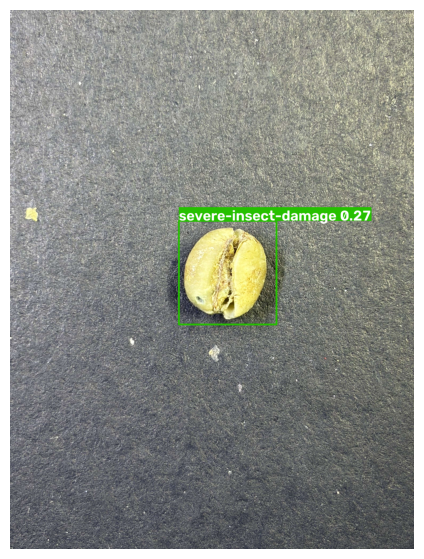

In [25]:
new_image = r"C:\xampp\htdocs\YOLO-COFFEE-TRAINING-6C\B015-BB-B1.jpg"

results_new = model.predict(
    source=new_image,
    conf=0.25,
    imgsz=640,
    device=device,
    save=True
)

for result in results_new:
    plt.figure(figsize=(10, 7))
    plt.imshow(result.plot()[:, :, ::-1])
    plt.axis("off")
    plt.show()